**AICE Associate <font color=red>모의고사 (문제)</font>** — AICE_Asso_008_공식형_분류_건물에너지수요예측

### **건물 데이터를 활용한 <span style="color:darkgreen">피크 수요 여부</span> 예측**
---

- 도메인 : 건물 에너지 수요 예측
- 목  표 : 피크 시간대 전력 수요 발생 여부를 예측하는 인공지능모델 개발
- 피크 요금 부담이 커져 그루파워의 고객 건물은 전력 수요를 미리 예측할 필요가 있다.
- 에너지관리팀은 기상·운영 데이터로 시간대별 수요를 예측해 절감 방안을 찾으려 한다.
- 건물 790건 안팎의 이력 데이터를 활용할 수 있다.
- 피크 수요 여부를 미리 알 수 있다면 그루파워의 운영 효율이 크게 개선될 것으로 보고 있다.

---

#### **[유의사항]**
- 답안 형태는 두 가지입니다. ① **결과 변수 저장형** — 가이드가 지정한 변수(예: `X_train`, `model`)에 결과를 저장하면 그 변수의 내용으로 채점합니다. ② **정답 입력형** — 코드 셀 **맨 아래** `정답NN`(빈칸이 여럿이면 `정답NN_1`, `정답NN_2`) 변수에 **값만** 입력합니다.
- 맨 위 **자동 채점 준비** 셀을 먼저 실행하면, 문항마다 `채점(번호)` 셀로 바로 ✅/❌ 를 확인하고 맨 끝 `채점()` 셀로 총점을 볼 수 있습니다.
- 숫자는 문항이 안내한 자릿수로 반올림해 입력하고, 글자는 따옴표로 감싸 입력하세요(예: `정답01 = 'pandas'`).
- 답을 구하는 코드는 문항의 작업 셀에 작성하고 실행하세요. 제공된 문항 셀을 삭제하지 마세요.
- 문항에 변수명이 제시된 경우 반드시 해당 변수명을 사용하세요. 앞 문항의 결과를 뒤 문항이 이어서 사용합니다.
- 막히면 문항 아래 접혀 있는 **힌트 1·2·3단계**를 순서대로 펼쳐 보세요. 단계가 올라갈수록 정답에 가까워집니다.
- 모든 데이터는 가상으로 생성한 합성데이터이며, 실제 AICE 시험문항의 원문을 복제하지 않았습니다.

#### **[학습 정보]**
- 학습 목표 : 그루파워의 데이터로 피크 시간대 전력 수요 발생 여부를 예측하는 AI 모델을 만들며 데이터 분석·전처리·모델링 전 과정을 수행할 수 있다
- AICE 역량 : 데이터 분석(DA1 분석 환경 구성, DA2 데이터 불러오기·구조 파악, DA3 탐색적 데이터 분석) / 데이터 전처리(DP1 이상치 처리, DP2 결측치 처리, DP3 인코딩·변수 변환, DP4 데이터 분할, DP5 스케일링) / AI 모델링(AM1 머신러닝 모델 학습·탐색, AM2 모델 해석, AM3 모델 성능 평가, AM4 딥러닝 모델 구성·학습, AM5 딥러닝 학습 결과 분석)
- 기술 스택 : pandas(import pandas as pd, read_json, head, select_dtypes, columns, loc, quantile, reset_index, drop, dropna, sum, isnull, get_dummies, info, DataFrame, sort_values, shape) · seaborn(barplot) · matplotlib(import matplotlib.pyplot as plt, show, plot, title, xlabel, ylabel, legend) · scikit-learn(train_test_split, StandardScaler, fit_transform, transform, PCA, KNeighborsClassifier, fit, DecisionTreeClassifier, feature_importances_, predict, accuracy_score) · TensorFlow(Keras)(Sequential, EarlyStopping, compile, fit, Dense, Activation, Dropout, history)
- 난이도 : 공식형(중급) (설계 난이도 점수 2.84 / 5)
- 예상 소요 시간 : 약 126분 (문항별 시간은 각 문항 제목 아래)
- 관련 도메인 : 건물 에너지 수요 예측 (에너지)

**[ 데이터 컬럼 설명 (데이터 파일명: data.json) ]**

- Serial_No             : 일련번호
- Outdoor_Temp          : 외기 온도(℃)
- Humidity              : 상대 습도(%)
- Hour                  : 시각(시)
- Floor_Area            : 연면적(천㎡)
- Occupancy             : 재실 인원 비율(%)
- Solar_Rad             : 일사량(MJ/㎡)
- Chiller_Cop           : 냉동기 효율(COP)
- Lag_Load_Kw           : 전일 동시각 전력(kW)
- Building_Type         : 건물 용도
- Region                : 지역
- Day_Type              : 요일 구분
- Peak_Flag             : 피크 수요 여부 (0: Normal, 1: Peak)

## <font color=blue>**<데이터 분석 (20점)>**</font>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요.**

In [20]:
import numpy as np
import seaborn as sns

### **1. 그래프 시각화에 널리 사용되는 파이썬 라이브러리 matplotlib 를 사용하려고 합니다. 별칭(alias)을 plt 로 해서 불러오세요.**

<sub>학습 목표: 분석에 필요한 파이썬 라이브러리를 관용 별칭으로 불러올 수 있다 | 역량: DA1 분석 환경 구성 | 기술: matplotlib(import matplotlib.pyplot as plt) | 난이도: 기초 | 예상 시간: 3분</sub>

- 불러올 라이브러리 : `matplotlib.pyplot`
- as 뒤에 쓸 이름(alias) : `plt`
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답01]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답01]** 의 값만 코드 셀 맨 아래에 `정답01 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

In [21]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

import matplotlib.pyplot as plt


In [3]:
# (1) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요

정답01 = 'plt'

<details><summary>힌트 1단계 (접근 방향) - 1번 문항</summary>

`import 라이브러리 as 별칭` 문법으로 라이브러리를 불러옵니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 1번 문항</summary>

사용할 도구: `import ... as ...`. 정답은 3글자이고 첫 글자는 `p` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 1번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import matplotlib.pyplot as pl_

정답01 = 'pl_'   # 빈칸에 넣은 단어
```

</details>

### **2. 모델을 만들 데이터를 파일에서 읽어 들이려 합니다. pandas로 데이터 파일을 읽어온 뒤, 데이터프레임 변수명 data 에 할당하고 첫 4개 행을 출력하세요.**

<sub>학습 목표: CSV 파일을 데이터프레임으로 읽고 행·열 구성을 확인할 수 있다 | 역량: DA2 데이터 불러오기·구조 파악 | 기술: pandas(import pandas as pd, read_json, head) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 제시된 가이드에 맞춰 코드를 작성하고 실행하세요
    - 대상 파일 : data.json
    - 읽은 결과를 담을 변수 : data
    - 파일은 이 노트북과 같은 폴더에 있습니다
    - 파일 형식은 JSON(records) 입니다
- **[결과 변수]** 결과는 반드시 `data` 변수에 저장하세요 — 변수의 내용(모양·값)으로 채점합니다
- 확인 : 코드 셀 맨 아래 확인 줄(`print(data.shape)`)을 실행하세요. LMS 에서는 이 출력값을 입력합니다
- 배점 : 5점

---

In [22]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

import pandas as pd

data = pd.read_json('aa22-m3-data.json')
data.head(4)

print(data.shape)

(792, 13)


In [ ]:
# (2) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
(792, 13)

<details><summary>힌트 1단계 (접근 방향) - 2번 문항</summary>

파일 형식(csv/json/구분자)에 맞는 pandas 읽기 함수와 옵션을 고르세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 2번 문항</summary>

사용할 도구: `pd.read_json`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 2번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 결과는 `data` 변수에 저장되고, 마지막 줄의 출력이 확인값입니다.
```python
import pandas as pd

data = pd.read_json('./data.json')
data.head(4)

# [data] 결과 확인 (LMS 에는 이 출력값을 입력)
print(data.shape)
```

</details>

### **3. 데이터의 컬럼들 중 자료형이 같은 것만 골라 따로 다루려 합니다.**

<sub>학습 목표: 집계·통계량으로 데이터의 특징을 탐색할 수 있다 | 역량: DA3 탐색적 데이터 분석 | 기술: pandas(select_dtypes, columns) | 난이도: 쉬움 | 예상 시간: 4분</sub>

- 앞 문항 결과 사용 : 2번 `data`
- data 에서 **수치형** 컬럼만 `select_dtypes` 로 선택해 `selected` 에 보관하세요
    - 선택된 컬럼 이름 목록을 `tolist()` 로 만들어 `selected_cols` 에 담으세요
- 아래 코드 셀의 빈칸 `< blank03_1 >`, `< blank03_2 >`, `< blank03_3 >` 를 채우고 실행하세요
- 빈칸에 들어갈 내용(함수·인자·모듈 이름)을 코드 셀 맨 아래 `정답03_1`, `정답03_2`, `정답03_3` 변수에 각각 저장하세요
    - 예시) 정답03_0 = 'data'
- 배점 : 5점

---

In [23]:
# (코드 셀) 코드의 빈칸(< blank >)을 채우고, 맨 아래 정답 변수에 빈칸의 내용을 입력한 뒤 실행하세요

selected = data.select_dtypes(include='number')
selected_cols = selected.columns.tolist()



In [ ]:
# (3) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요

정답03_1 = 'select_dtypes'
정답03_2 = 'include'
정답03_3 = 'tolist'


<details><summary>힌트 1단계 (접근 방향) - 3번 문항</summary>

자료형을 기준으로 컬럼을 고르는 DataFrame 메서드와 include/exclude 옵션을 쓰세요. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 3번 문항</summary>

사용할 도구: `select_dtypes`, `tolist`. 정답은 13글자이고 첫 글자는 `s` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 3번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
selected = data.select_______(incl___='number')
selected_cols = selected.columns.tol___()

정답03_1 = 'select_______'   # 빈칸 1에 넣은 단어
정답03_2 = 'incl___'   # 빈칸 2에 넣은 단어
정답03_3 = 'tol___'   # 빈칸 3에 넣은 단어
```

</details>

### **4. 행 번호가 아니라 **Serial_No** 값으로 데이터를 바로 찾을 수 있게 인덱스를 바꾸려 합니다.**

<sub>학습 목표: 집계·통계량으로 데이터의 특징을 탐색할 수 있다 | 역량: DA3 탐색적 데이터 분석 | 기술: pandas(loc) | 난이도: 보통 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 2번 `data`
- data 의 Serial_No 컬럼을 인덱스로 지정(`set_index`)해 `idx_df` 에 보관하세요
    - `loc` 로 인덱스가 **559** 인 행의 Chiller_Cop 값을 `row_val` 에 담으세요
    - `idx_df` 를 인덱스 기준으로 오름차순 정렬(`sort_index`)해 `sorted_df` 에 담으세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답04]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답04]** 의 값만 코드 셀 맨 아래에 `정답04 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

In [24]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

idx_df = data.set_index('Serial_No')
row_val = idx_df.loc[559, 'Chiller_Cop']
sorted_df = idx_df.sort_index()


In [ ]:
# (4) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요

정답04 = 'sort_index'


<details><summary>힌트 1단계 (접근 방향) - 4번 문항</summary>

인덱스로 쓸 컬럼을 지정한 뒤, 행 이름과 컬럼 이름으로 값을 선택합니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 4번 문항</summary>

사용할 도구: `set_index`, `loc`, `sort_index`. 정답은 10글자이고 첫 글자는 `s` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 4번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
idx_df = data.set_index('Serial_No')
row_val = idx_df.loc[559, 'Chiller_Cop']
sorted_df = idx_df.sort______()

정답04 = 'sort______'   # 빈칸에 넣은 단어
```

</details>

## <font color=blue>**<데이터 전처리 (30점)>**</font>

### **5. 재실 인원 비율(%)(Occupancy) 컬럼의 이상치를 IQR 기준으로 제거하려 합니다. 제시된 가이드에 맞춰 처리하세요.**

<sub>학습 목표: 사분위 범위(IQR) 등의 기준으로 이상치를 찾아 처리할 수 있다 | 역량: DP1 이상치 처리 | 기술: pandas(quantile, reset_index, drop) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 2번 `data`
- 아래 안내대로 코드를 작성하고 실행하세요
    - 대상 데이터프레임 : data
    - 사분위수(Q1, Q3)와 IQR 을 산출하세요
    - lower_fence = Q1 - 1.5 x IQR, upper_fence = Q3 + 1.5 x IQR 로 정의하세요
    - Occupancy 이(가) 두 fence 밖에 있는 행을 삭제하세요
    - 식별자 컬럼 Serial_No 도 삭제하고 인덱스를 0부터 다시 매겨 data_temp 에 보관하세요
- **[결과 변수]** 결과는 반드시 `data_temp` 변수에 저장하세요 — 변수의 내용(모양·값)으로 채점합니다
- 확인 : 코드 셀 맨 아래 확인 줄(`print(data_temp.shape)`)을 실행하세요. LMS 에서는 이 출력값을 입력합니다
- 배점 : 6점

---

In [25]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

q1 = data['Occupancy'].quantile(0.25)
q3 = data['Occupancy'].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

is_out = (data['Occupancy'] > upper_fence) | (data['Occupancy'] < lower_fence)
data_temp = data[~is_out].drop(columns=['Serial_No']).reset_index(drop=True)

print(data_temp.shape)

(766, 12)


In [ ]:
# (5) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요

(766, 12)


<details><summary>힌트 1단계 (접근 방향) - 5번 문항</summary>

분위수로 fence 를 계산하고, 범위 밖 여부를 불리언으로 만든 뒤 반대로 선택합니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 5번 문항</summary>

사용할 도구: `quantile`, `drop`, `reset_index`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 5번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 결과는 `data_temp` 변수에 저장되고, 마지막 줄의 출력이 확인값입니다.
```python
q1 = data['Occupancy'].quantile(0.25)
q3 = data['Occupancy'].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

is_out = (data['Occupancy'] > upper_fence) | (data['Occupancy'] < lower_fence)
data_temp = data[~is_out].drop(columns=['Serial_No']).reset_index(drop=True)

# [data_temp] 결과 확인 (LMS 에는 이 출력값을 입력)
print(data_temp.shape)
```

</details>

### **6. 데이터에 결측치가 있을 경우 AI모델링의 성능이 저하될 수 있습니다. AI모델링할 때 부정적 영향이 없도록 아래 가이드에 따라 결측치를 처리하십시오.**

<sub>학습 목표: 결측치를 확인하고 삭제하거나 대체할 수 있다 | 역량: DP2 결측치 처리 | 기술: pandas(dropna, sum, isnull) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 5번 `data_temp`
- 대상 데이터프레임 : data_temp
- 결측치 개수를 확인한 후에 결측치가 있는 행을 모두 삭제하세요
- 전처리가 반영된 데이터프레임은 변수명 data_na 에 담으세요
- 결측치가 사라졌는지 확인하세요
- 아래 코드 셀의 빈칸 `< blank06_1 >`, `< blank06_2 >` 를 채우고 실행하세요
- 빈칸에 들어갈 내용(함수·인자·모듈 이름)을 코드 셀 맨 아래 `정답06_1`, `정답06_2` 변수에 각각 저장하세요
    - 예시) 정답06_0 = 'data'
- 배점 : 6점

---

In [26]:
# (코드 셀) 코드의 빈칸(< blank >)을 채우고, 맨 아래 정답 변수에 빈칸의 내용을 입력한 뒤 실행하세요

print( '결측치 처리 전\n', data_temp.isnull().sum() )
data_na = data_temp.dropna()
print( '결측치 처리 후\n', data_na.isnull().sum() )


결측치 처리 전
 Outdoor_Temp      0
Humidity          0
Hour              0
Floor_Area       30
Occupancy         0
Solar_Rad         0
Chiller_Cop       0
Lag_Load_Kw      29
Building_Type     0
Region           35
Day_Type          0
Peak_Flag         0
dtype: int64
결측치 처리 후
 Outdoor_Temp     0
Humidity         0
Hour             0
Floor_Area       0
Occupancy        0
Solar_Rad        0
Chiller_Cop      0
Lag_Load_Kw      0
Building_Type    0
Region           0
Day_Type         0
Peak_Flag        0
dtype: int64


In [ ]:
# (6) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요

정답06_1 = 'isnull'
정답06_2 = 'dropna'


<details><summary>힌트 1단계 (접근 방향) - 6번 문항</summary>

빈칸을 채워 코드를 완성한 뒤 실행하세요. 결측치 여부를 True/False 로 돌려주는 메서드입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 6번 문항</summary>

사용할 도구: `isnull`, `sum`, `dropna`. 정답은 6글자이고 첫 글자는 `i` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 6번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
print( '결측치 처리 전\n', data_temp.isn___().sum() )
data_na = data_temp.dro___()
print( '결측치 처리 후\n', data_na.isnull().sum() )

정답06_1 = 'isn___'   # 빈칸 1에 넣은 단어
정답06_2 = 'dro___'   # 빈칸 2에 넣은 단어
```

</details>

### **7. 원-핫 인코딩은 범주형 데이터를 1과 0의 이진형 벡터로 변환하는 방법입니다. 제시된 가이드에 맞춰 범주형 데이터를 변환하는 코드를 수정하세요.**

<sub>학습 목표: 범주형 변수를 인코딩하고 변수를 정리·변환할 수 있다 | 역량: DP3 인코딩·변수 변환 | 기술: pandas(get_dummies, info) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 2번 `pd` · 6번 `data_na`
- 제시된 가이드에 맞춰 인코딩하는데 에러가 나고 있습니다. 코드의 오류를 바로잡으세요
    - 대상 데이터프레임 : data_na
    - 문자열(범주형) 컬럼 Building_Type, Region, Day_Type 을(를) get_dummies 로 인코딩하세요 (타깃 Peak_Flag 은 제외, drop_first=False)
    - 인코딩된 데이터프레임은 data_preset 에 저장하고 info() 로 구조를 확인하세요
- **[정답07]** 인코딩 후 data_preset 의 **전체 컬럼 개수**는 몇 개입니까?
- 답안 : **[정답07]** 의 값만 코드 셀 맨 아래에 `정답07 = 값` 형태로 입력하세요
- 오류는 2곳입니다 — 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 부분도 바로잡으세요
- 배점 : 6점

---

In [27]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

data_preset = pd.get_dummies(data=data_na, columns=['Building_Type', 'Region', 'Day_Type'], drop_first=False)
data_preset.info()

data_preset.shape[1]


<class 'pandas.core.frame.DataFrame'>
Index: 674 entries, 0 to 765
Data columns (total 21 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Outdoor_Temp       674 non-null    float64
 1   Humidity           674 non-null    int64  
 2   Hour               674 non-null    int64  
 3   Floor_Area         674 non-null    float64
 4   Occupancy          674 non-null    float64
 5   Solar_Rad          674 non-null    float64
 6   Chiller_Cop        674 non-null    float64
 7   Lag_Load_Kw        674 non-null    float64
 8   Peak_Flag          674 non-null    int64  
 9   Building_Type_병원   674 non-null    bool   
 10  Building_Type_상가   674 non-null    bool   
 11  Building_Type_오피스  674 non-null    bool   
 12  Building_Type_학교   674 non-null    bool   
 13  Region_경기          674 non-null    bool   
 14  Region_서울          674 non-null    bool   
 15  Region_영남          674 non-null    bool   
 16  Region_충청          674 non-null

21

In [ ]:
# (7) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요

정답07 = '21'


<details><summary>힌트 1단계 (접근 방향) - 7번 문항</summary>

고칠 곳은 2군데입니다. 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 줄도 찾으세요. get_dummies 호출의 인자 이름을 점검하세요. 인코딩이 끝난 데이터프레임의 컬럼 개수를 확인하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 7번 문항</summary>

사용할 도구: `shape`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 7번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd

data_preset = pd.get_dummies(data=data_na, columns=['Building_Type', 'Region', 'Day_Type'], drop_first=False)
data_preset.info()

# [정답07] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
data_preset.shape[__]
```

</details>

### **8. 훈련과 검증 데이터셋을 분리하고, 검증 레이블의 분포를 확인할 계획입니다.**

<sub>학습 목표: 피처와 레이블을 나누고 훈련·검증 데이터로 분할할 수 있다 | 역량: DP4 데이터 분할 | 기술: pandas(drop) · scikit-learn(train_test_split) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 7번 `data_preset`
- 아래 안내대로 코드를 작성하고 실행하세요
    - 대상 데이터프레임 : data_preset
    - 피크 수요 여부(Peak_Flag) 컬럼을 레이블값 y 로, 나머지 컬럼을 피처값 X 로 대입하세요
    - 변수명 : X_train, X_valid, y_train, y_valid (훈련 피처/검증 피처/훈련 레이블/검증 레이블)
    - 데이터를 훈련 65 : 검증 35 로 분할합니다 (train_size=0.65)
    - 분리에는 sklearn.model_selection 의 train_test_split 을 사용하세요
    - random_state 는 42 로 고정하세요
- **[결과 변수]** 결과는 반드시 `X_valid` 변수에 저장하세요 — 변수의 내용(모양·값)으로 채점합니다
- 확인 : 코드 셀 맨 아래 확인 줄(`print(len(X_valid))`)을 실행하세요. LMS 에서는 이 출력값을 입력합니다
- 배점 : 6점

---

In [28]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

from sklearn.model_selection import train_test_split

X = data_preset.drop('Peak_Flag', axis=1)
y = data_preset['Peak_Flag']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, train_size=0.65, random_state=42)

print(len(X_valid))

236


In [ ]:
# (8) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
236

<details><summary>힌트 1단계 (접근 방향) - 8번 문항</summary>

피처와 레이블을 나눈 뒤, 훈련/검증으로 무작위 분할합니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 8번 문항</summary>

사용할 도구: `train_test_split`, `drop`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 8번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 결과는 `X_valid` 변수에 저장되고, 마지막 줄의 출력이 확인값입니다.
```python
from sklearn.model_selection import train_test_split

X = data_preset.drop('Peak_Flag', axis=1)
y = data_preset['Peak_Flag']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, train_size=0.65, random_state=42)

# [X_valid] 결과 확인 (LMS 에는 이 출력값을 입력)
print(len(X_valid))
```

</details>

### **9. 변수가 많을 때는 정보 손실을 최소화하면서 차원을 줄일 수 있습니다. 스케일링 후 PCA 를 처리하세요.**

<sub>학습 목표: 훈련 데이터로 스케일러를 학습해 검증 데이터에 같은 기준을 적용할 수 있다 | 역량: DP5 스케일링 | 기술: scikit-learn(StandardScaler, fit_transform, transform, PCA) | 난이도: 어려움 | 예상 시간: 12분</sub>

- 앞 문항 결과 사용 : 8번 `X_train`, `X_valid`
- 다음 지침에 따라 코드를 작성하고 실행하세요
    - StandardScaler 로 X_train 은 fit_transform, X_valid 는 transform 해 각각 X_train, X_valid 에 다시 저장하세요
    - PCA(n_components=0.95, random_state=7) 를 `pca` 에 지정하세요 (n_components 가 0~1 사이 실수이면 "설명 분산 비율이 그 값 이상이 되는 최소 주성분 수"를 자동으로 고릅니다). 스케일링된 X_train 으로 학습·변환해 X_train_pca 에, X_valid 를 변환해 X_valid_pca 에 담으세요
- **[결과 변수]** 결과는 반드시 `pca` 변수에 저장하세요 — 변수의 내용(모양·값)으로 채점합니다
- 확인 : 코드 셀 맨 아래 확인 줄(`print(pca.n_components)`)을 실행하세요. LMS 에서는 이 출력값을 입력합니다
- 배점 : 6점

---

In [30]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

ss = StandardScaler()
X_train = ss.fit_transform(X_train)
X_valid = ss.transform(X_valid)

pca = PCA(n_components=0.95, random_state=7)
X_train_pca = pca.fit_transform(X_train)
X_valid_pca = pca.transform(X_valid)

print(pca.n_components)

0.95


In [31]:
# (9) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
0.95

0.95

<details><summary>힌트 1단계 (접근 방향) - 9번 문항</summary>

스케일링 후, 주성분 분석기를 훈련 데이터로 학습해 변환합니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 9번 문항</summary>

사용할 도구: `StandardScaler`, `PCA`, `fit_transform`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 9번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 결과는 `pca` 변수에 저장되고, 마지막 줄의 출력이 확인값입니다.
```python
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

ss = StandardScaler()
X_train = ss.fit_transform(X_train)
X_valid = ss.transform(X_valid)

pca = PCA(n_components=0.95, random_state=7)
X_train_pca = pca.fit_transform(X_train)
X_valid_pca = pca.transform(X_valid)

# [pca] 결과 확인 (LMS 에는 이 출력값을 입력)
print(pca.n_components)
```

</details>

## <font color=blue>**<AI 모델링 (50점)>**</font>

### **10. 피크 수요 여부(Peak_Flag)을(를) 예측하는 머신러닝 모델을 만들려고 합니다. KNN와(과) DecisionTree는 각각 서로 다른 방식으로 예측하는 모델입니다.**

<sub>학습 목표: 머신러닝 모델에 하이퍼파라미터를 지정해 학습하고 결과를 확인할 수 있다 | 역량: AM1 머신러닝 모델 학습·탐색 | 기술: scikit-learn(KNeighborsClassifier, fit, DecisionTreeClassifier) | 난이도: 쉬움 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_train` · 9번 `X_train`
- KNN 모델을 아래와 같이 만들어 `knn` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : n_neighbors=7, weights='distance'
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- DecisionTree 모델을 아래와 같이 만들어 `dt` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : max_depth=8, min_samples_leaf=10
    - 난수 시드(random_state) : 7
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- **[정답10]** 학습된 `dt`(DecisionTree) 의 **실제 깊이** `dt.get_depth()` 는 얼마인가요?
- 답안 : **[정답10]** 의 값만 코드 셀 맨 아래에 `정답10 = 값` 형태로 입력하세요
- 배점 : 10점

---

In [32]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=7, weights='distance')
knn.fit(X_train, y_train)

from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(max_depth=8, min_samples_leaf=10, random_state=7)
dt.fit(X_train, y_train)

dt.get_depth()


7

In [ ]:
# (10) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요

정답10 = '7'


<details><summary>힌트 1단계 (접근 방향) - 10번 문항</summary>

모델 객체를 하이퍼파라미터와 함께 만들고 훈련 데이터로 fit 합니다. 결정나무 모델의 get_depth() 메서드를 호출하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 10번 문항</summary>

사용할 도구: `KNeighborsClassifier`, `fit`, `DecisionTreeClassifier`, `get_depth`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 10번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=7, weights='distance')
knn.fit(X_train, y_train)

from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(max_depth=8, min_samples_leaf=10, random_state=7)
dt.fit(X_train, y_train)

# [정답10] 실행한 결과를 입력하세요
dt.get_depth()
```

</details>

### **11. 모델의 해석력과 개선 방향을 이해하기 위해 DecisionTree 모델의 변수중요도를 파악하려고 합니다.**

<sub>학습 목표: 변수 중요도·계수로 모델이 어떤 변수에 의존하는지 해석할 수 있다 | 역량: AM2 모델 해석 | 기술: pandas(DataFrame, sort_values, columns) · seaborn(barplot) · matplotlib(show) · scikit-learn(feature_importances_) | 난이도: 보통 | 예상 시간: 12분</sub>

- 앞 문항 결과 사용 : 1번 `plt` · 2번 `pd` · 8번 `X` · 10번 `dt`
- 아래 가이드에 따라 모델의 변수중요도를 파악하는데 실행 중 예외가 발생합니다. 코드의 오류를 정정하세요
    - 앞서 학습시킨 DecisionTree 모델 `dt` 를 사용하세요
    - 변수중요도 점수와 변수 이름(X.columns)을 매핑하여 DataFrame(fi)을 만드세요
    - 변수중요도 점수를 기준으로 내림차순 정렬하고 Top 10 개만 선정하세요
    - 변수중요도 점수를 막대 그래프(seaborn barplot)로 시각화하세요
- **[정답11]** 출력된 그래프에서 **가장 높은 중요도**를 보이는 변수명을 쓰세요
- 답안 : **[정답11]** 의 값만 코드 셀 맨 아래에 `정답11 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 오류는 2곳입니다 — 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 부분도 바로잡으세요
- 배점 : 10점

---

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48337 (\N{HANGUL SYLLABLE BYEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50896 (\N{HANGUL SYLLABLE WEON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


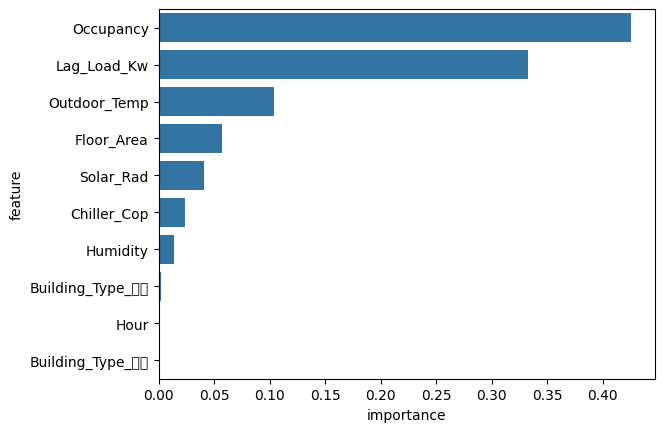

'Occupancy'

In [35]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

fi = pd.DataFrame({'feature': X.columns, 'importance': dt.feature_importances_})
fi = fi.sort_values('importance', ascending=False)[:10]
sns.barplot(x='importance', y='feature', data=fi)
plt.show()

fi.iloc[0]['feature']


In [ ]:
# (11) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요

정답11 = 'Occupancy'


<details><summary>힌트 1단계 (접근 방향) - 11번 문항</summary>

고칠 곳은 2군데입니다. 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 줄도 찾으세요. 변수 중요도를 DataFrame 으로 만들고 정렬해 그리는 흐름을 점검하세요. fi 의 첫 번째 행(가장 큰 중요도)의 feature 값을 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 11번 문항</summary>

사용할 도구: `sort_values`, `iloc`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 11번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

fi = pd.DataFrame({'feature': X.columns, 'importance': dt.feature_importances_})
fi = fi.sort_values('importance', ascending=False)[:10]
sns.barplot(x='importance', y='feature', data=fi)
plt.show()

# [정답11] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
fi['____'].iloc[__]
```

</details>

### **12. 앞서 학습시킨 KNN와(과) DecisionTree 모델의 성능을 평가하려고 합니다.**

<sub>학습 목표: 평가 지표로 두 모델의 성능을 비교할 수 있다 | 역량: AM3 모델 성능 평가 | 기술: scikit-learn(predict, accuracy_score) | 난이도: 쉬움 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_valid` · 9번 `X_valid` · 10번 `dt`, `knn`
- 아래 가이드에 따라 각 모델의 Accuracy(정확도) 를 산출하려는데 오류가 발생하고 있습니다. 코드의 오류를 정정하세요
    - 앞서 학습시킨 knn 와 dt 모델을 사용하세요
    - 성능 평가는 **검증데이터셋(X_valid, y_valid)** 을 활용하세요
    - 두 모델의 Accuracy(정확도) 값을 각각 knn_score, dt_score 변수에 저장하고 출력하세요
- **[정답12]** 두 모델의 Accuracy(정확도) 결과를 비교했을 때, 성능이 **더 우수한** 모델은 무엇인가요? (KNN / DecisionTree 중 하나)
- 답안 : **[정답12]** 의 값만 코드 셀 맨 아래에 `정답12 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 오류는 3곳입니다 — 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 부분도 바로잡으세요
- 배점 : 10점

---

In [38]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

from sklearn.metrics import accuracy_score

y_pred_knn = knn.predict(X_valid)
y_pred_dt = dt.predict(X_valid)

knn_score = accuracy_score(y_valid, y_pred_knn)
dt_score = accuracy_score(y_valid, y_pred_dt)
print(knn_score, dt_score)


0.7923728813559322 0.8305084745762712


In [ ]:
# (12) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요

정답12 = 'DecisionTree'

<details><summary>힌트 1단계 (접근 방향) - 12번 문항</summary>

고칠 곳은 3군데입니다. 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 줄도 찾으세요. Accuracy(정확도) 를 계산하는 흐름(예측 -> 지표 함수)을 점검하세요. 값이 클수록 우수한 지표입니다. 두 점수를 비교하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 12번 문항</summary>

가이드에 언급된 함수를 확인하세요.

</details>

<details><summary>힌트 3단계 (전체 코드) - 12번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
from sklearn.metrics import accuracy_score

y_pred_knn = knn.predict(X_valid)
y_pred_dt = dt.predict(X_valid)

knn_score = accuracy_score(y_valid, y_pred_knn)
dt_score = accuracy_score(y_valid, y_pred_dt)
print(knn_score, dt_score)

# [정답12] 실행한 결과를 입력하세요
print(knn_score, dt_score)
```

</details>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요. (tensorflow 필요)**

In [39]:
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model, load_model
from tensorflow.keras.layers import Input, Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam, RMSprop, Nadam, SGD
from tensorflow.keras.regularizers import l2
from tensorflow.keras.utils import to_categorical

tf.random.set_seed(100)

### **13. 피크 수요 여부(Peak_Flag)을(를) 예측하는 딥러닝 모델을 만들려고 합니다. 아래 가이드를 참고해서 모델링하고 학습을 수행하세요.**

<sub>학습 목표: 주어진 구조대로 Keras 딥러닝 모델을 구성하고 학습할 수 있다 | 역량: AM4 딥러닝 모델 구성·학습 | 기술: pandas(shape) · TensorFlow(Keras)(Sequential, EarlyStopping, compile, fit) | 난이도: 어려움 | 예상 시간: 17분</sub>

- 앞 문항 결과 사용 : 8번 `y_train`, `y_valid` · 9번 `X_train`, `X_valid`
- 아래 **모델 구조도(topology)** 와 가이드를 함께 참고하세요
- 아래 조건대로 모델을 구현하고 학습하세요
    - tensorflow framework 를 사용하세요
    - 은닉층은 Dense 레이어 2개(노드 수 [16, 8])로 쌓되, 활성화 함수 'tanh' 는 Dense 의 인자가 아니라 **바로 뒤에 `Activation('tanh')` 층을 따로 추가**하는 방식으로 처리하세요 (출력층은 Dense 의 activation 인자를 그대로 사용)
    - EarlyStopping 으로 10번의 epoch 동안 val_loss 가 향상되지 않으면 훈련을 중지(restore_best_weights=True)하도록 설정하고 estop 변수에 담으세요
    - 모든 은닉층 뒤에 Dropout(0.5) 층을 두세요
    - 출력층: 노드 1개, 활성화 함수 'sigmoid'
    - compile 설정 : optimizer='adam', loss='binary_crossentropy', metrics=[accuracy]
    - batch_size 는 16, epochs 는 20 로 학습하고 학습정보는 history 변수에 보관하세요 (검증 데이터: X_valid, 검증 레이블)
    - 안내하지 않은 파라미터는 지정하지 마세요
- **[결과 변수]** 모델은 `model`, 학습 기록은 `history` 변수에 저장하세요 — 모델 구조(층 수·파라미터 수)와 학습 설정으로 채점합니다
- 확인 : 코드 셀 맨 아래 `print(model.count_params())` 출력값을 LMS 에 입력합니다
- 배점 : 10점

---

**[모델 구조도]**

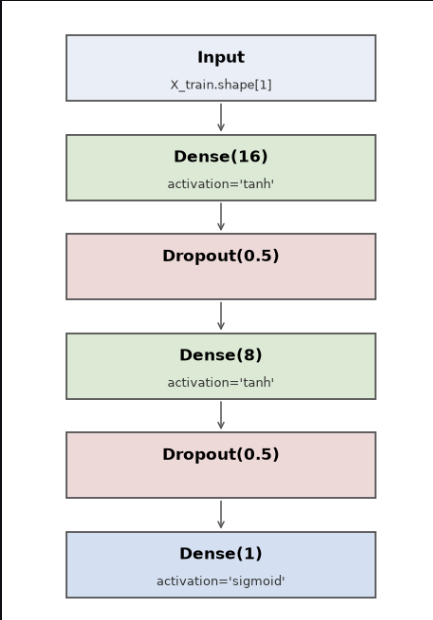


In [40]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

model = Sequential([
    Dense(16, input_dim=X_train.shape[1]),
    Activation('tanh'),
    Dropout(0.5),
    Dense(8),
    Activation('tanh'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

estop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
cb_list = [estop]

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

history = model.fit(X_train, y_train,
                    epochs=20, batch_size=16,
                    validation_data=(X_valid, y_valid),
                    callbacks=cb_list)

print(model.count_params())


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 4s 66ms/step - accuracy: 0.5091 - loss: 0.7685 - val_accuracy: 0.5763 - val_loss: 0.6808
Epoch 2/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.5594 - loss: 0.6966 - val_accuracy: 0.6314 - val_loss: 0.6519
Epoch 3/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.6050 - loss: 0.6542 - val_accuracy: 0.6737 - val_loss: 0.6277
Epoch 4/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.6279 - loss: 0.6590 - val_accuracy: 0.7034 - val_loss: 0.6080
Epoch 5/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.6210 - loss: 0.6631 - val_accuracy: 0.7331 - val_loss: 0.5899
Epoch 6/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.6461 - loss: 0.6225 - val_accuracy: 0.7458 - val_loss: 0.5713
Epoch 7/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.6461 - loss: 0.6336 - val_accuracy: 0.7669 - val_loss: 0.5552
Epoch 8/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7100 - loss: 0.5862 - val_accuracy: 0.7669 - v

In [ ]:
# (13) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
481

<details><summary>힌트 1단계 (접근 방향) - 13번 문항</summary>

각 은닉 Dense 층 바로 뒤에 활성화 함수 층을 하나씩 추가하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 13번 문항</summary>

사용할 도구: `Sequential`, `Dense`, `Activation`, `Dropout`, `EarlyStopping`, `model.compile`, `model.fit`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 13번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 결과는 `model` 변수에 저장되고, 마지막 줄의 출력이 확인값입니다.
```python
model = Sequential([
    Dense(16, input_dim=X_train.shape[1]),
    Activation('tanh'),
    Dropout(0.5),
    Dense(8),
    Activation('tanh'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

estop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
cb_list = [estop]

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

history = model.fit(X_train, y_train,
                    epochs=20, batch_size=16,
                    validation_data=(X_valid, y_valid),
                    callbacks=cb_list)

# [model] 결과 확인 (LMS 에는 이 출력값을 입력)
print(model.count_params())
```

</details>

### **14. 앞서 만든 딥러닝 모델의 일반화 성능을 평가하려고 합니다. matplotlib 라이브러리를 활용해서, 학습 Loss와(과) 검증 Loss의 변화를 그래프로 시각화하십시오.**

<sub>학습 목표: 학습 기록으로 딥러닝 모델의 학습 과정과 성능을 분석할 수 있다 | 역량: AM5 딥러닝 학습 결과 분석 | 기술: matplotlib(plot, title, xlabel, ylabel) · TensorFlow(Keras)(history) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 1번 `plt` · 13번 `history`
- 학습 Loss 과 검증 Loss 를 한 그래프(1개)에 함께 그리세요
- 그래프의 타이틀은 'Model Loss' 로, X축 이름은 'Epochs', Y축 이름은 'Loss' 로 표시하세요
- legend 에는 'train', 'val' 를 쓰세요
- 아래 코드 셀의 빈칸 `< blank14_1 >`, `< blank14_2 >` 를 채우고 실행하세요
- 빈칸에 들어갈 내용(함수·인자·모듈 이름)을 코드 셀 맨 아래 `정답14_1`, `정답14_2` 변수에 각각 저장하세요
    - 예시) 정답14_0 = 'data'
- 배점 : 10점

---

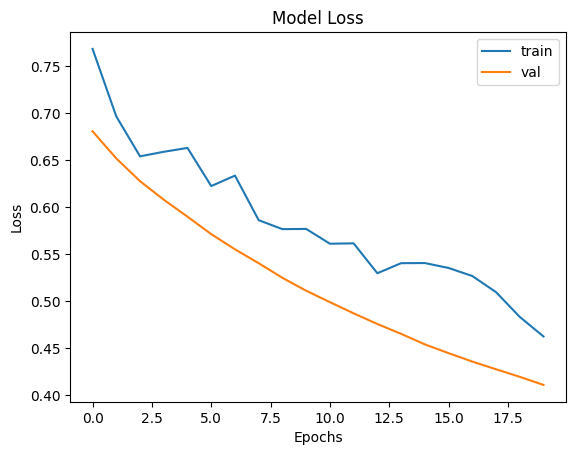

In [42]:
# (코드 셀) 코드의 빈칸(< blank >)을 채우고, 맨 아래 정답 변수에 빈칸의 내용을 입력한 뒤 실행하세요

import matplotlib.pyplot as plt

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(['train', 'val'])
plt.show()


In [ ]:
# (14) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요

정답14_1 = 'history'
정답14_2 = 'title'


<details><summary>힌트 1단계 (접근 방향) - 14번 문항</summary>

빈칸을 채워 코드를 완성한 뒤 실행하세요. 그래프 제목을 지정하는 matplotlib 함수입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 14번 문항</summary>

사용할 도구: `plt.plot`, `plt.title`, `plt.xlabel`, `plt.ylabel`, `plt.legend`, `plt.show`. 정답은 5글자이고 첫 글자는 `t` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 14번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import matplotlib.pyplot as plt

plt.plot(hist___.history['loss'])
plt.plot(history.history['val_loss'])
plt.tit__('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(['train', 'val'])
plt.show()

정답14_1 = 'hist___'   # 빈칸 1에 넣은 단어
정답14_2 = 'tit__'   # 빈칸 2에 넣은 단어
```

</details>